# How text becomes music

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dorienh/music-ai-explained/blob/main/05-how-text-becomes-music/notebook.ipynb)

Companion to the article *How Text Becomes Music*. We follow a prompt through a text encoder, work attention and contrastive training by hand, test a joint text-audio model (CLAP) on real recordings, look for what it cannot see, and measure what guidance does.

Runs on a CPU. The first run downloads about 1.5 GB of model weights, plus 2 GB more for the optional MusicGen section.

In [1]:
import sys
if "google.colab" in sys.modules:
    !pip install -q librosa soundfile "transformers>=4.45"

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, librosa, matplotlib.pyplot as plt
from IPython.display import Audio, display

BLUE, ORANGE, AQUA, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "lines.linewidth": 2, "figure.dpi": 110})

def clip(name, sr=None, offset=0.0, duration=None):
    """Load one of librosa's freely licensed example recordings (downloaded on first use)."""
    y, sr = librosa.load(librosa.example(name, hq=True), sr=sr, mono=True, offset=offset, duration=duration)
    return y, sr
import torch
from transformers import AutoTokenizer, T5EncoderModel, ClapModel, ClapProcessor, logging
logging.set_verbosity_error(); torch.set_grad_enabled(False); np.set_printoptions(precision=2, suppress=True)
cosine = lambda a, b: float(torch.nn.functional.cosine_similarity(a, b, dim=-1))

## 1. From a sentence to tokens to vectors

T5 is the text encoder inside MusicGen. It was trained on text only.

In [3]:
tok = AutoTokenizer.from_pretrained("t5-base")
t5 = T5EncoderModel.from_pretrained("t5-base").eval()

ids = tok("sad jazz with brushed drums", return_tensors="pt")
print("pieces:", tok.convert_ids_to_tokens(ids.input_ids[0]))
print("ids:   ", ids.input_ids[0].tolist())
print("output:", tuple(t5(**ids).last_hidden_state.shape), "= (sentences, tokens, numbers per token)")
print("vocabulary:", tok.vocab_size, "| encoder parameters:", round(sum(p.numel() for p in t5.parameters()) / 1e6), "million")

pieces: ['▁sad', '▁jazz', '▁with', '▁', 'brushed', '▁drum', 's', '</s>']
ids:    [6819, 9948, 28, 3, 24865, 5253, 7, 1]
output: (1, 8, 768) = (sentences, tokens, numbers per token)
vocabulary: 32100 | encoder parameters: 110 million


## 2. Vectors that know their context

Cosine similarity by hand, then the word "bass" in three sentences. Before the encoder its vector is the same everywhere. After the encoder it depends on the sentence.

In [4]:
a, b = np.array([1.0, 2.0]), np.array([2.0, 1.0])
print("cosine similarity of (1,2) and (2,1):", (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b)))

def word_vector(sentence, word):
    enc = tok(sentence, return_tensors="pt")
    i = [k for k, p in enumerate(tok.convert_ids_to_tokens(enc.input_ids[0])) if p.strip("▁") == word][0]
    return t5(**enc).last_hidden_state[0, i], t5.get_input_embeddings()(enc.input_ids)[0, i]

A, A_in = word_vector("a deep bass line with heavy drums", "bass")
B, _ = word_vector("a slow bass groove on an upright", "bass")
C, C_in = word_vector("we caught a bass in the lake", "bass")
print("before the encoder, identical:", bool(torch.allclose(A_in, C_in)))
print(f"after the encoder: music vs music {cosine(A, B):.2f}, music vs fishing {cosine(A, C):.2f}")

cosine similarity of (1,2) and (2,1): 0.7999999999999998
before the encoder, identical: True
after the encoder: music vs music 0.88, music vs fishing 0.59


## 3. Cross-attention by hand

Each text token offers a key and a value. The music position being generated forms a query. Scores are query · key, softmax turns them into weights, and the output is the weighted average of the values.

In [5]:
keys = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
values = np.array([[10.0, 0.0], [0.0, 10.0], [5.0, 5.0]])
query = np.array([2.0, 0.5])                       # try other queries

scores = keys @ query
weights = np.exp(scores) / np.exp(scores).sum()
print("scores: ", scores); print("weights:", weights); print("output: ", weights @ values)

scores:  [2.  0.5 2.5]
weights: [0.35 0.08 0.57]
output:  [6.35 3.65]


## 4. Contrastive training by hand

Rows are texts, columns are audio clips, matching pairs on the diagonal. The loss for each row is the negative log of the probability given to the correct clip.

In [6]:
similarity = np.array([[0.8, 0.1, 0.3], [0.2, 0.7, 0.1], [0.4, 0.2, 0.6]])
temperature = 0.2
p = np.exp(similarity / temperature); p /= p.sum(axis=1, keepdims=True)
print("probability on the correct clip:", np.diag(p)); print("loss per row:", -np.log(np.diag(p)), " mean:", round(float(-np.log(np.diag(p)).mean()), 3))

probability on the correct clip: [0.9  0.88 0.67]
loss per row: [0.11 0.12 0.41]  mean: 0.213


## 5. CLAP on real recordings

Eight recordings, eight plain captions, every caption against every clip.

sanity check, jazz vs metal: 0.43 (should be well below 1)


matching pairs 0.47, mismatched pairs 0.22
captions whose best clip is the right one: 6 of 8


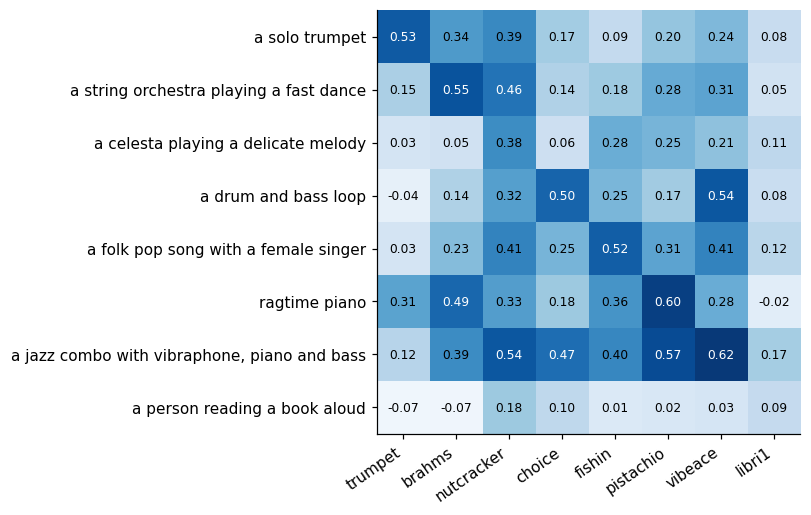

In [7]:
name = "laion/clap-htsat-unfused"
clap, proc = ClapModel.from_pretrained(name).eval(), ClapProcessor.from_pretrained(name)
normalize = lambda x: torch.nn.functional.normalize(x, dim=-1)
embed_audio = lambda waves: normalize(clap.get_audio_features(**proc(audios=waves, sampling_rate=48000, return_tensors="pt")))
embed_text = lambda texts: normalize(clap.get_text_features(**proc(text=texts, return_tensors="pt", padding=True)))

# always check an embedding model on two things you know are different
check = embed_text(["sad jazz with brushed drums", "heavy metal with distorted guitars"])
print(f"sanity check, jazz vs metal: {float(check[0] @ check[1]):.2f} (should be well below 1)")

clips = {"trumpet": (0, "a solo trumpet"), "brahms": (0, "a string orchestra playing a fast dance"), "nutcracker": (0, "a celesta playing a delicate melody"),
         "choice": (0, "a drum and bass loop"), "fishin": (30, "a folk pop song with a female singer"), "pistachio": (0, "ragtime piano"),
         "vibeace": (0, "a jazz combo with vibraphone, piano and bass"), "libri1": (0, "a person reading a book aloud")}
waves = [clip(n, sr=48000, offset=o, duration=10)[0] for n, (o, _) in clips.items()]
captions = [c for _, c in clips.values()]
M = (embed_text(captions) @ embed_audio(waves).T).numpy()

n = len(clips)
print(f"matching pairs {np.diag(M).mean():.2f}, mismatched pairs {(M.sum() - np.trace(M)) / (n * n - n):.2f}")
print(f"captions whose best clip is the right one: {(M.argmax(1) == np.arange(n)).sum()} of {n}")
fig, ax = plt.subplots(figsize=(9, 5)); ax.imshow(M, cmap="Blues", vmin=-0.1, vmax=0.65); ax.grid(False)
for i in range(n):
    for j in range(n): ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if M[i, j] > 0.42 else "black")
ax.set_yticks(range(n)); ax.set_yticklabels(captions); ax.set_xticks(range(n)); ax.set_xticklabels(list(clips), rotation=35, ha="right"); plt.show()

## 6. What CLAP cannot see

Pairs of prompts compared text against text. If two prompts land on nearly the same point, nothing downstream can tell them apart. Add your own pairs.

In [8]:
pairs = [("sad jazz with brushed drums", "heavy metal with distorted guitars"), ("a slow drum loop", "a fast drum loop"),
         ("sad jazz with brushed drums", "melancholic jazz with soft brush drumming"), ("jazz with drums", "jazz without drums"),
         ("piano, then drums", "drums, then piano"), ("sad jazz with brushed drums", "happy jazz with brushed drums"),
         ("a song in a major key", "a song in a minor key")]
for a, b in pairs:
    e = embed_text([a, b]); print(f"{float(e[0] @ e[1]):.2f}   {a!r}  |  {b!r}")

0.43   'sad jazz with brushed drums'  |  'heavy metal with distorted guitars'
0.75   'a slow drum loop'  |  'a fast drum loop'
0.85   'sad jazz with brushed drums'  |  'melancholic jazz with soft brush drumming'
0.90   'jazz with drums'  |  'jazz without drums'


0.92   'piano, then drums'  |  'drums, then piano'
0.93   'sad jazz with brushed drums'  |  'happy jazz with brushed drums'
0.97   'a song in a major key'  |  'a song in a minor key'


Tempo, on the audio side: the same drum loop slowed to 60% and sped up to 160%.

In [9]:
drum = waves[list(clips).index("choice")]
slow = librosa.effects.time_stretch(drum, rate=0.6)[:480000]
fast = librosa.effects.time_stretch(np.tile(drum, 2), rate=1.6)[:480000]
S = (embed_audio([slow, fast]) @ embed_text(["a slow drum loop", "a fast drum loop"]).T).numpy()
print("              'slow'  'fast'"); print("slowed clip  ", S[0]); print("sped-up clip ", S[1])
print("slowed"); display(Audio(slow[:240000], rate=48000)); print("sped up"); display(Audio(fast[:240000], rate=48000))

              'slow'  'fast'
slowed clip   [0.33 0.14]
sped-up clip  [0.3  0.15]
slowed


[audio player: run the cell to listen]


sped up


[audio player: run the cell to listen]


In [10]:
T = embed_text(["music with drums", "music without drums"])
for label, wave in (("drum loop", drum), ("solo trumpet", waves[0])):
    s = (T @ embed_audio([wave]).T).squeeze().tolist(); print(f"{label:13s} 'music with drums' {s[0]:.2f}   'music without drums' {s[1]:.2f}")

drum loop     'music with drums' 0.38   'music without drums' 0.19
solo trumpet  'music with drums' 0.12   'music without drums' 0.05


## 7. Does guidance make the music follow the prompt? (optional, downloads MusicGen)

Two prompts at guidance scale 1 (off) and 3, scored with CLAP against both prompts. The article's table uses four prompts, three scales and two seeds (`guidance_vs_prompt.py`).

In [11]:
RUN_MUSICGEN = True
if RUN_MUSICGEN:
    from transformers import AutoProcessor, MusicgenForConditionalGeneration
    mg_proc = AutoProcessor.from_pretrained("facebook/musicgen-small")
    musicgen = MusicgenForConditionalGeneration.from_pretrained("facebook/musicgen-small").eval()
    prompts = ["sad jazz with brushed drums", "fast techno with a heavy kick drum"]
    P = embed_text(prompts)
    for i, prompt in enumerate(prompts):
        inputs = mg_proc(text=[prompt], padding=True, return_tensors="pt")
        for scale in (1.0, 3.0):
            torch.manual_seed(0)
            audio = musicgen.generate(**inputs, do_sample=True, guidance_scale=scale, max_new_tokens=250)[0, 0].numpy()
            s = (P @ embed_audio([librosa.resample(audio, orig_sr=32000, target_sr=48000)]).T).squeeze().tolist()
            print(f"{prompt!r}, guidance {scale:g}: similarity to own prompt {s[i]:.2f}, to the other {s[1 - i]:.2f}")
            display(Audio(audio, rate=32000))

'sad jazz with brushed drums', guidance 1: similarity to own prompt 0.40, to the other 0.13


[audio player: run the cell to listen]


'sad jazz with brushed drums', guidance 3: similarity to own prompt 0.41, to the other -0.02


[audio player: run the cell to listen]


'fast techno with a heavy kick drum', guidance 1: similarity to own prompt 0.09, to the other 0.25


[audio player: run the cell to listen]


'fast techno with a heavy kick drum', guidance 3: similarity to own prompt 0.44, to the other 0.00


[audio player: run the cell to listen]


## Where next

- The articles: [Music & AI on Medium](https://medium.com/@dorien-herremans/list/music-ai-3fb88d4826dd)
- For the full picture: [A Tutorial on Generative Models for Music Audio](https://arxiv.org/abs/2610.38252)